# UTS Data Mining — Tahap 2: Data Understanding & Preprocessing Plan
**Tema:** Analisis Karakteristik Data Sensor Industrial Multivariat dan Pemodelan Klasterisasi Deret Waktu
**Dataset:** Pump Sensor Data (Kaggle) — 52 sensor, resolusi 1 menit, Apr–Agu 2018
**Tujuan analisis:** *operational condition clustering* (mengelompokkan kondisi operasional pompa), **bukan** anomaly detection.

**Cakupan notebook ini (sesuai instruksi Tahap 2):**
1. Analisis taksonomi & skala → statistik deskriptif (mean, std, skewness, dll.)
2. Analisis korelasi & outlier → matriks korelasi antar-sensor, boxplot, scatter plot
3. Rancangan preprocessing (hasilnya jadi input Tahap 3: desain klasterisasi)

**Catatan label:** file sumber memiliki `machine_status`. Kolom ini dikeluarkan dari seluruh fitur dan proses clustering. Jadi pemodelan tetap unsupervised, tetapi data sumber memiliki label referensi yang ditahan; penggunaan label hanya untuk evaluasi eksternal pasca-clustering harus dikonfirmasi kepada dosen.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# ====== KONFIGURASI ======
DATA_CANDIDATES = [Path("archive/sensor.csv"), Path("Dataset/archive/sensor.csv"), Path("sensor.csv"), Path("/content/sensor.csv")]
DATA_PATH = next((str(p) for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("sensor.csv tidak ditemukan. Jalankan dari folder proyek/Dataset atau unggah ke /content.")
OUTPUT_DIR = Path("Dataset") if Path("Dataset/archive/sensor.csv").exists() else Path(".")
MISSING_THRESHOLD = 0.05        # sensor dengan missing > 5% dibuang
INTERP_LIMIT = 60               # interpolasi hanya untuk gap <= 60 menit
RANDOM_STATE = 42
SAMPLE_N = 20000                # sampel untuk plot berat (histogram, scatter)

## 1. Load Data & Penghapusan Label
Kolom `Unnamed: 0` dan `machine_status` tidak dipakai sebagai fitur. Label status tetap dianggap sebagai informasi referensi yang ditahan, bukan masukan clustering. `timestamp` dijadikan index agar urutan waktu tetap terjaga.

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Ukuran data mentah:", raw.shape)

LABEL_COLS = ["machine_status"]
df = raw.drop(columns=["Unnamed: 0"] + LABEL_COLS, errors="ignore")
del raw

df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.set_index("timestamp").sort_index()

assert "machine_status" not in df.columns, "Label masih ada!"
sensor_cols = df.columns.tolist()
print(f"Setelah label dihapus: {df.shape[0]:,} baris x {df.shape[1]} sensor")
df.head()

Ukuran data mentah: (220320, 55)
Setelah label dihapus: 220,320 baris x 52 sensor


                     sensor_00  sensor_01  ...  sensor_50  sensor_51
timestamp                                  ...                      
2018-04-01 00:00:00   2.465394   47.09201  ...   243.0556   201.3889
2018-04-01 00:01:00   2.465394   47.09201  ...   243.0556   201.3889
2018-04-01 00:02:00   2.444734   47.35243  ...   241.3194   203.7037
2018-04-01 00:03:00   2.460474   47.09201  ...   240.4514   203.1250
2018-04-01 00:04:00   2.445718   47.13541  ...   242.1875   201.3889

[5 rows x 52 columns]

## 2. Analisis Taksonomi Data

In [3]:
print("Periode      :", df.index.min(), "->", df.index.max())
print("Durasi       :", df.index.max() - df.index.min())
print("Interval antar-rekaman:")
print(df.index.to_series().diff().value_counts().head())
print("\nTimestamp duplikat :", df.index.duplicated().sum())
print("Baris duplikat     :", df.duplicated().sum())

taksonomi = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_valid": df.notna().sum(),
    "n_unik": df.nunique(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
taksonomi["tipe"] = np.where(taksonomi["n_unik"] > 20, "numerik kontinu", "numerik diskret/konstan")
print("\nRingkasan tipe atribut:")
print(taksonomi["tipe"].value_counts())
taksonomi

Periode      : 2018-04-01 00:00:00 -> 2018-08-31 23:59:00
Durasi       : 152 days 23:59:00
Interval antar-rekaman:
timestamp
0 days 00:01:00    220319
Name: count, dtype: int64

Timestamp duplikat : 0
Baris duplikat     : 2878

Ringkasan tipe atribut:
tipe
numerik kontinu            51
numerik diskret/konstan     1
Name: count, dtype: int64


             dtype  n_valid  n_unik  missing_%                     tipe
sensor_00  float64   210112    1253       4.63          numerik kontinu
sensor_01  float64   219951     831       0.17          numerik kontinu
sensor_02  float64   220301     831       0.01          numerik kontinu
sensor_03  float64   220301     588       0.01          numerik kontinu
sensor_04  float64   220301    7844       0.01          numerik kontinu
sensor_05  float64   220301  190751       0.01          numerik kontinu
sensor_06  float64   215522     812       2.18          numerik kontinu
sensor_07  float64   214869     531       2.47          numerik kontinu
sensor_08  float64   215213     626       2.32          numerik kontinu
sensor_09  float64   215725     565       2.09          numerik kontinu
sensor_10  float64   220301  198804       0.01          numerik kontinu
sensor_11  float64   220301  196368       0.01          numerik kontinu
sensor_12  float64   220301  187145       0.01          numerik 

**Poin yang perlu ditulis di paper:** data berupa deret waktu multivariat dengan interval seragam 1 menit, atribut seluruhnya numerik kontinu (memenuhi syarat ≥ 5 atribut kontinu), dan tidak ada label klaster setelah `machine_status` dibuang.

**Baris berulang:** ada 2.878 baris sensor yang nilainya sama dengan baris lain, tetapi tidak ada timestamp duplikat. Baris tersebut dipertahankan karena pengukuran yang sama pada waktu berbeda dapat merepresentasikan operasi stabil; tidak dianggap duplikasi rekaman tanpa bukti lebih lanjut.


## 3. Missing Values
Pola missing dilihat dari dua sisi: persentase dan **panjang gap berurutan**. Gap yang panjang berarti sensor mati berhari-hari, sehingga tidak layak diisi interpolasi.

In [4]:
def longest_gap(s):
    m = s.isna()
    g = (m != m.shift()).cumsum()
    return int(m.groupby(g).sum().max())

miss = pd.DataFrame({
    "missing_%": df.isna().mean() * 100,
    "gap_terpanjang_menit": df.apply(longest_gap),
})
miss["gap_terpanjang_hari"] = (miss["gap_terpanjang_menit"] / 1440).round(2)
miss = miss[miss["missing_%"] > 0].sort_values("missing_%", ascending=False)
print("Baris yang seluruh sensornya kosong:", df.isna().all(axis=1).sum())
miss.round(2).head(15)

Baris yang seluruh sensornya kosong: 11


           missing_%  gap_terpanjang_menit  gap_terpanjang_hari
sensor_15     100.00                220320               153.00
sensor_50      34.96                 76996                53.47
sensor_51       6.98                 15356                10.66
sensor_00       4.63                  6076                 4.22
sensor_07       2.47                  4668                 3.24
sensor_08       2.32                  4227                 2.94
sensor_06       2.18                  4299                 2.99
sensor_09       2.09                  4212                 2.92
sensor_01       0.17                   200                 0.14
sensor_30       0.12                   239                 0.17
sensor_29       0.03                    41                 0.03
sensor_32       0.03                    35                 0.02
sensor_18       0.02                    15                 0.01
sensor_17       0.02                    15                 0.01
sensor_22       0.02                    

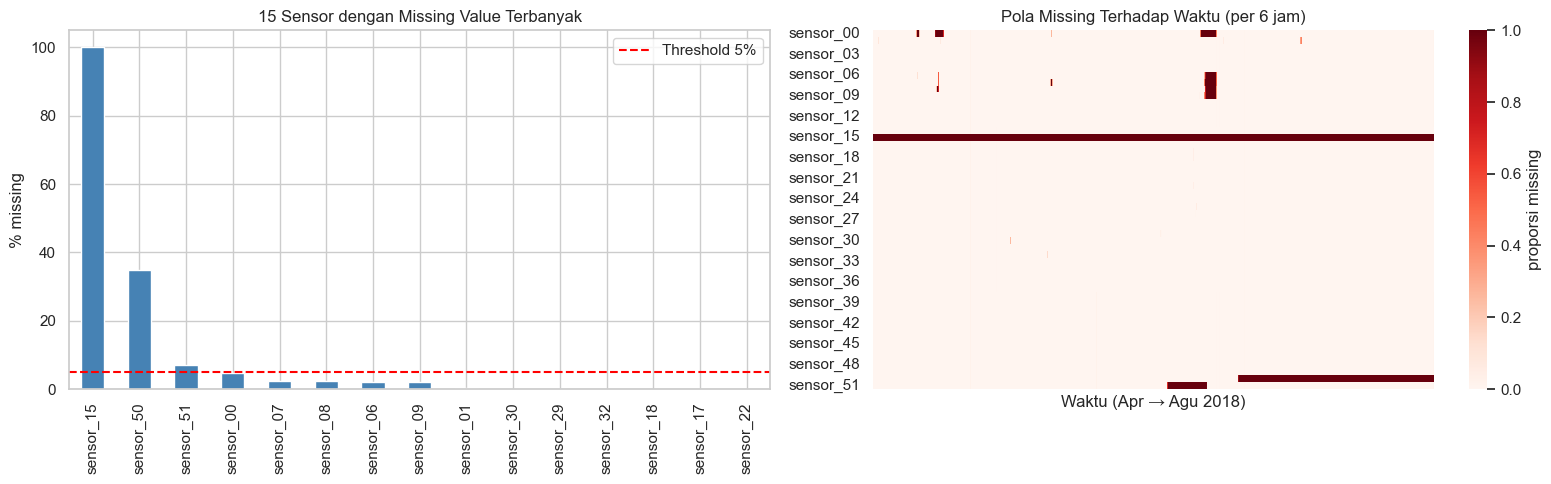

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

m_all = (df.isna().mean() * 100).sort_values(ascending=False)
m_all.head(15).plot.bar(ax=ax[0], color="steelblue")
ax[0].axhline(MISSING_THRESHOLD * 100, color="red", ls="--", label=f"Threshold {MISSING_THRESHOLD*100:.0f}%")
ax[0].set_title("15 Sensor dengan Missing Value Terbanyak")
ax[0].set_ylabel("% missing")
ax[0].legend()

# Pola missing terhadap waktu (rata-rata per 6 jam)
mt = df.isna().resample("6h").mean().T
sns.heatmap(mt, cmap="Reds", cbar_kws={"label": "proporsi missing"}, ax=ax[1], xticklabels=False)
ax[1].set_title("Pola Missing Terhadap Waktu (per 6 jam)")
ax[1].set_xlabel("Waktu (Apr → Agu 2018)")
plt.tight_layout()
plt.show()

**Keputusan:** sensor dengan missing > 5% dibuang (`sensor_15` kosong 100%; `sensor_50` dan `sensor_51` kosong dalam blok panjang). Missing pada sensor lain terjadi sebagai blok berurutan, bukan acak.

In [6]:
drop_sensors = m_all[m_all > MISSING_THRESHOLD * 100].index.tolist()
print("Sensor dibuang:", drop_sensors)
df_sel = df.drop(columns=drop_sensors)
feat_cols = df_sel.columns.tolist()
print("Sensor tersisa:", len(feat_cols))

Sensor dibuang: ['sensor_15', 'sensor_50', 'sensor_51']
Sensor tersisa: 49


## 4. Statistik Deskriptif & Analisis Skala
Dihitung pada data asli (sebelum imputasi) untuk 49 sensor yang dipertahankan.

In [7]:
desc = df_sel.describe().T
desc["skewness"] = df_sel.skew()
desc["kurtosis"] = df_sel.kurt()
desc["range"] = desc["max"] - desc["min"]
desc["IQR"] = desc["75%"] - desc["25%"]
desc["CV"] = (desc["std"] / desc["mean"].abs()).replace([np.inf, -np.inf], np.nan)
desc = desc[["count","mean","std","min","25%","50%","75%","max","range","IQR","skewness","kurtosis","CV"]]
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
desc

                count    mean     std    min  ...     IQR  skewness  kurtosis    CV
sensor_00 210,112.000   2.372   0.412  0.000  ...   0.061    -4.897    23.348 0.174
sensor_01 219,951.000  47.592   3.297  0.000  ...   3.168    -1.678     5.435 0.069
sensor_02 220,301.000  50.867   3.667 33.160  ...   2.387    -2.815     8.640 0.072
sensor_03 220,301.000  43.752   2.419 31.641  ...   2.474    -1.874     5.010 0.055
sensor_04 220,301.000 590.674 144.024  2.798  ...  10.995    -3.369     9.955 0.244
sensor_05 220,301.000  73.396  17.298  0.000  ...  10.936    -2.783     9.842 0.236
sensor_06 215,522.000  13.502   2.164  0.014  ...   1.194    -4.718    25.155 0.160
sensor_07 214,869.000  15.843   2.201  0.000  ...   0.521    -6.081    40.469 0.139
sensor_08 215,213.000  15.201   2.037  0.029  ...   0.514    -5.991    42.247 0.134
sensor_09 215,725.000  14.799   2.092  0.000  ...   0.065    -5.919    39.875 0.141
sensor_10 220,301.000  41.470  12.094  0.000  ...   6.758    -2.503     5.74

Sensor dengan std = 0 (konstan): []
Rasio std terbesar / terkecil : 759x
Rentang mean                  : 2.304 s.d. 922.6
Rentang range (max-min)       : 2.549 s.d. 2000.0

Kategori skewness:
skewness
sangat miring (>1)       42
miring sedang (0.5-1)     5
simetris (<0.5)           2
Name: count, dtype: int64


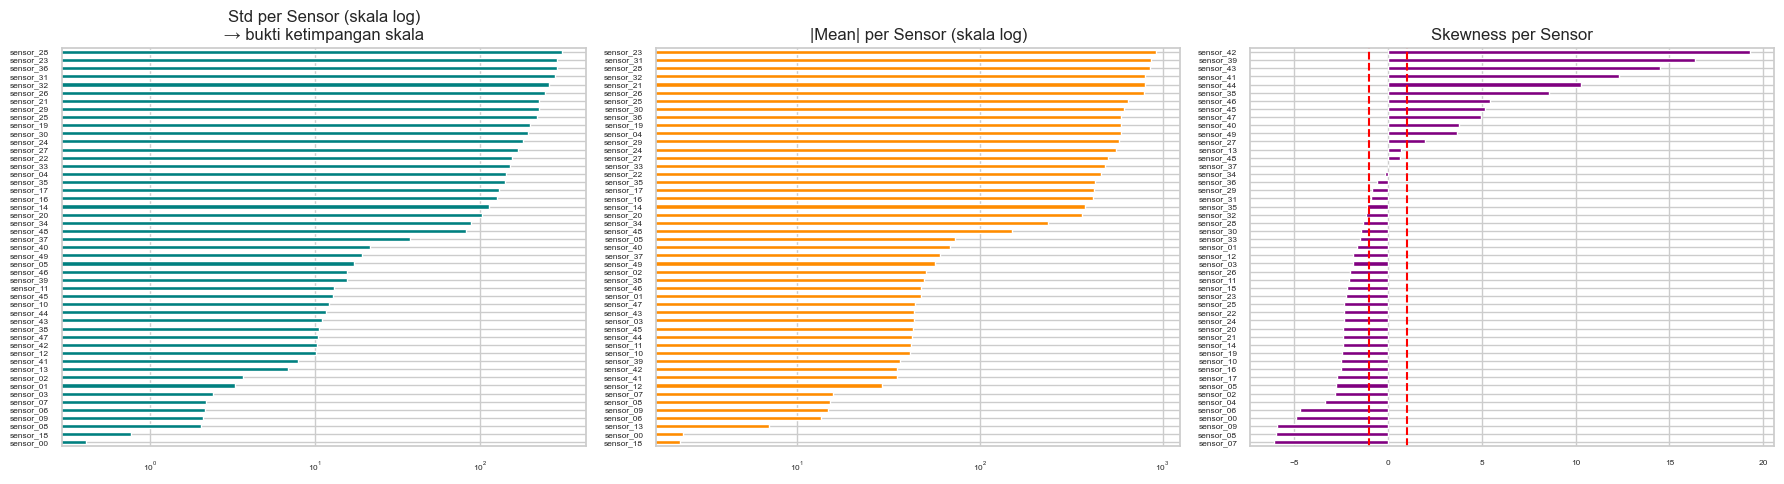

In [8]:
print("Sensor dengan std = 0 (konstan):", desc.index[desc["std"] == 0].tolist())

# --- Ketimpangan skala ---
ratio_std = desc["std"].max() / desc["std"][desc["std"] > 0].min()
print(f"Rasio std terbesar / terkecil : {ratio_std:,.0f}x")
print(f"Rentang mean                  : {desc['mean'].min():.3f} s.d. {desc['mean'].max():.1f}")
print(f"Rentang range (max-min)       : {desc['range'].min():.3f} s.d. {desc['range'].max():.1f}")

# --- Skewness ---
skew_cat = pd.cut(desc["skewness"].abs(), [-0.01, 0.5, 1, np.inf], labels=["simetris (<0.5)", "miring sedang (0.5-1)", "sangat miring (>1)"])
print("\nKategori skewness:")
print(skew_cat.value_counts())

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
desc["std"].sort_values().plot.barh(ax=ax[0], logx=True, color="teal", fontsize=6)
ax[0].set_title("Std per Sensor (skala log)\n→ bukti ketimpangan skala")
desc["mean"].abs().sort_values().plot.barh(ax=ax[1], logx=True, color="darkorange", fontsize=6)
ax[1].set_title("|Mean| per Sensor (skala log)")
desc["skewness"].sort_values().plot.barh(ax=ax[2], color="purple", fontsize=6)
ax[2].axvline(1, color="red", ls="--"); ax[2].axvline(-1, color="red", ls="--")
ax[2].set_title("Skewness per Sensor")
plt.tight_layout()
plt.show()

**Interpretasi:** rentang nilai antar-sensor sangat timpang (ada sensor bernilai ratusan, ada yang berkisar 0–1), sehingga jarak Euclidean pada data mentah akan didominasi sensor berskala besar. Ini menjadi dasar kuat untuk **scaling wajib** sebelum klasterisasi. Distribusi yang miring (|skew| > 1) menjadi pertimbangan memilih scaler yang tahan outlier.

### 4.1 Distribusi Tiap Sensor

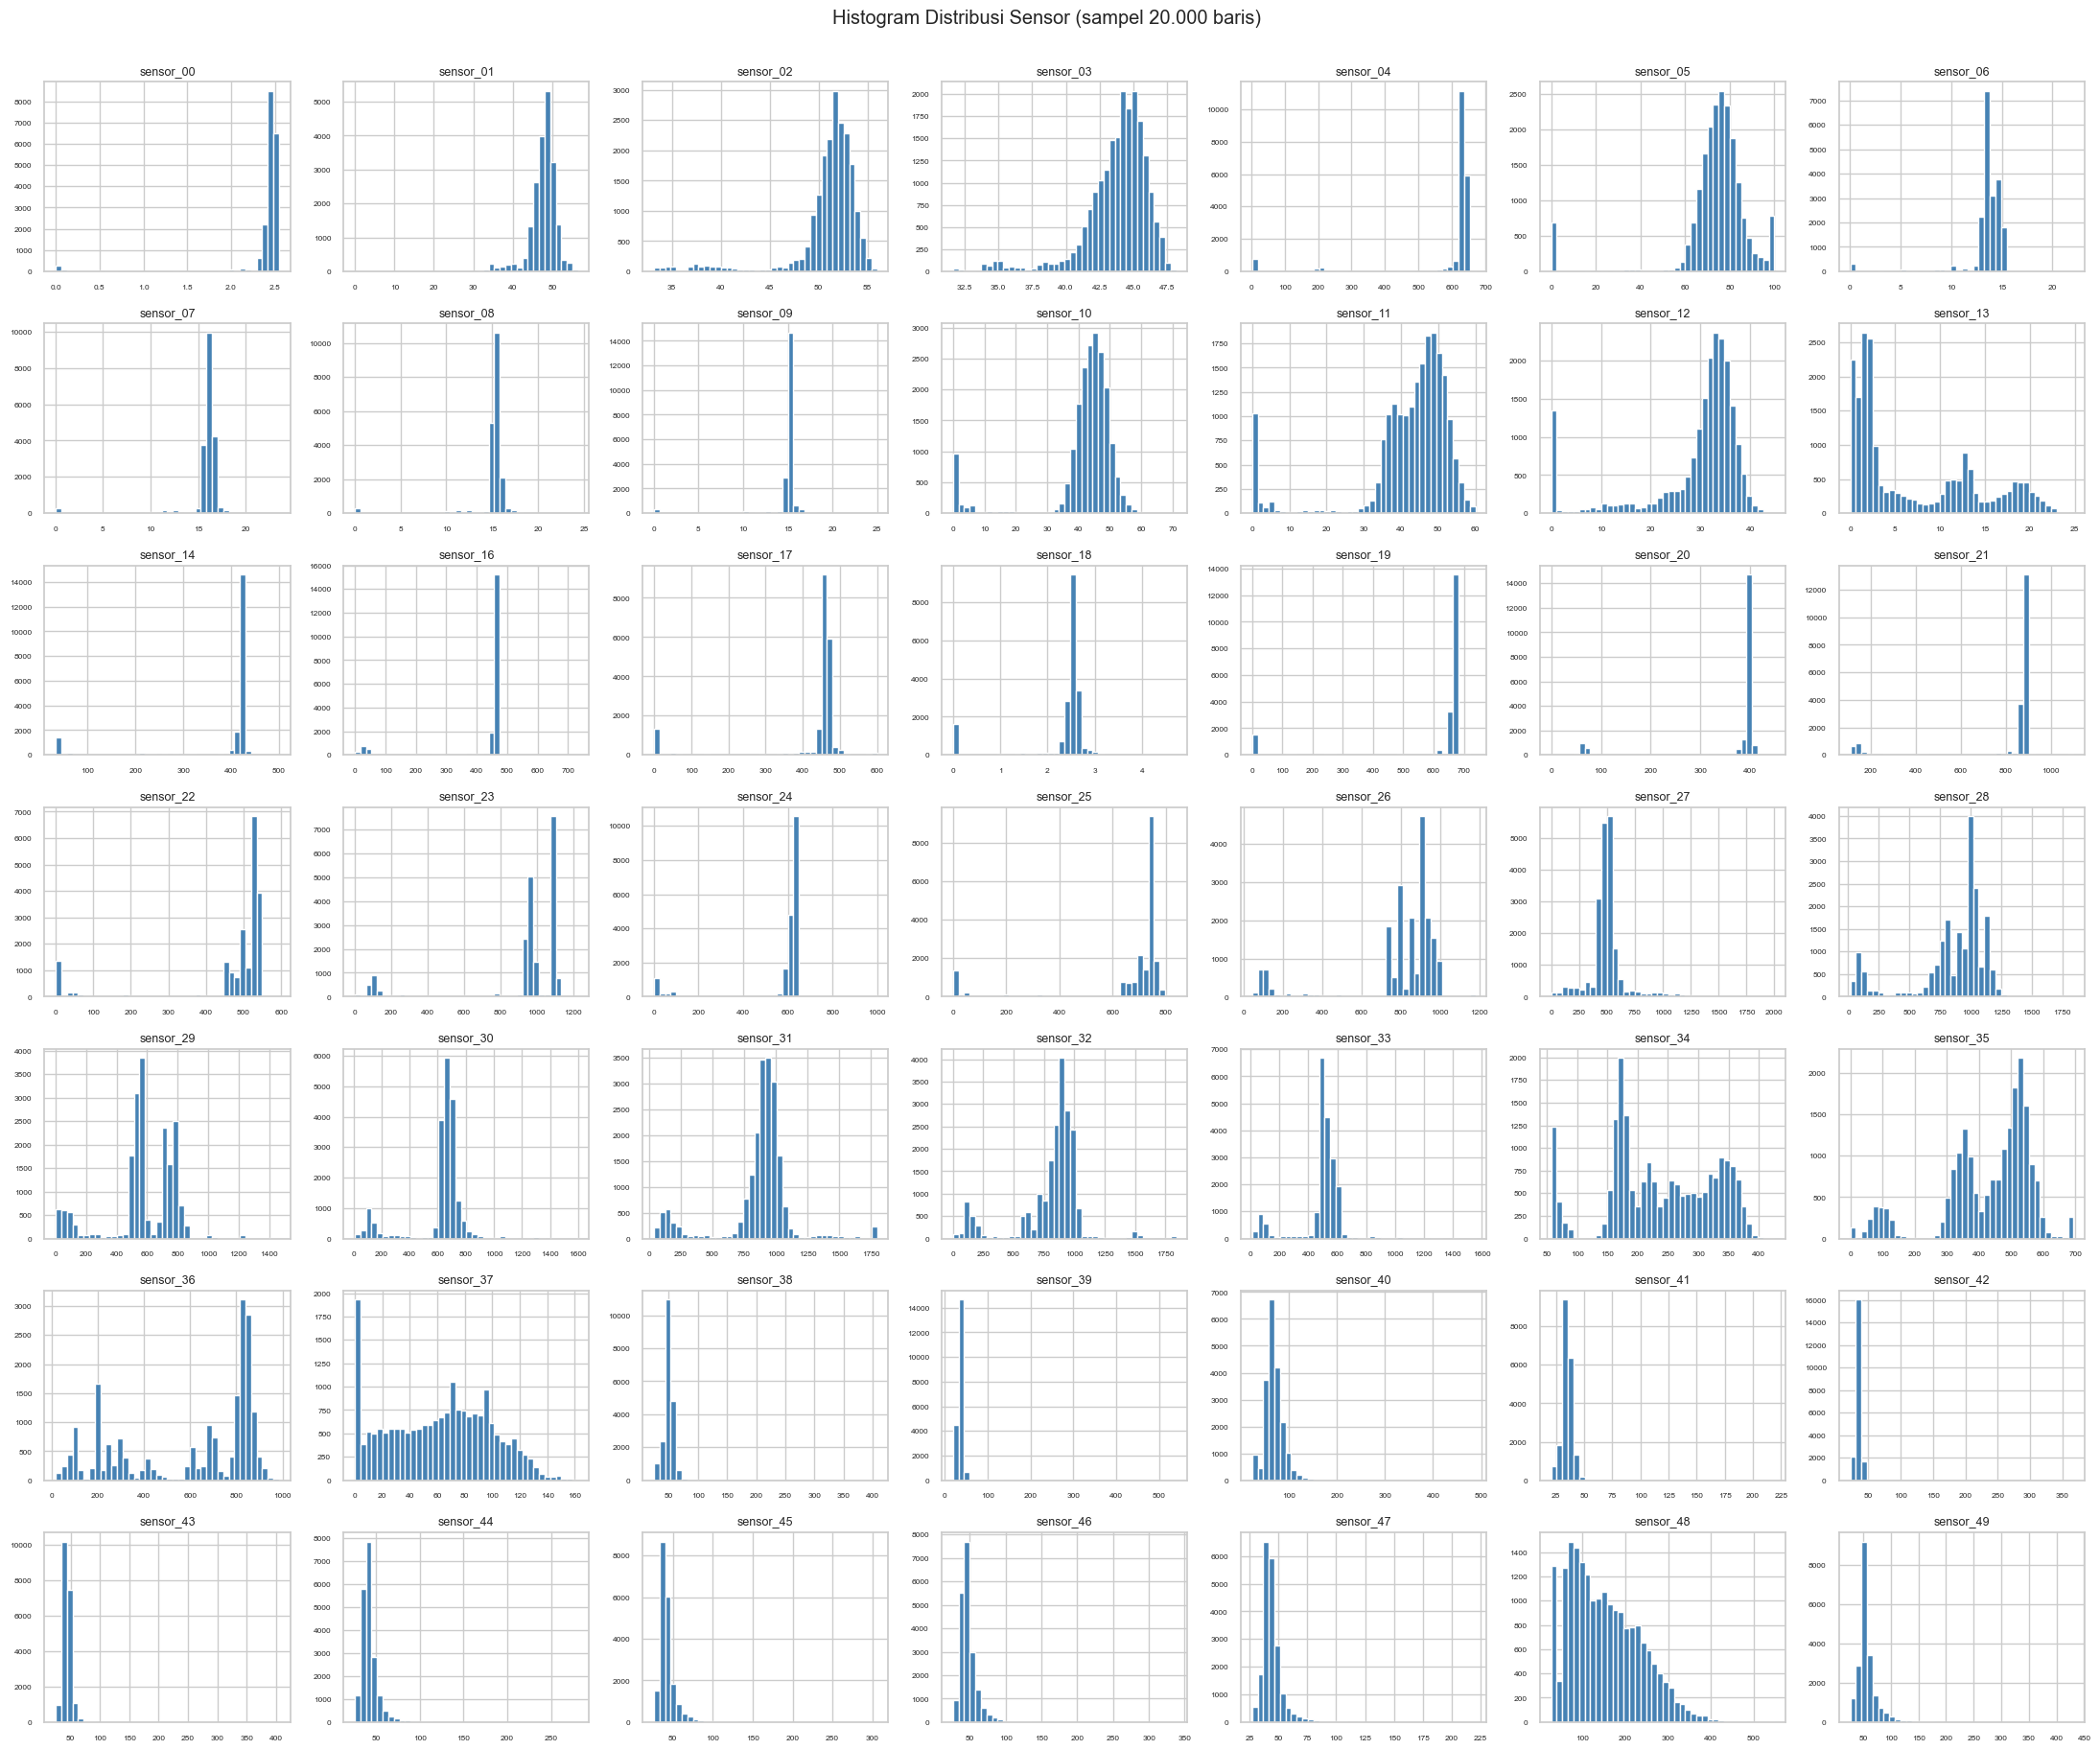

In [9]:
sample = df_sel.sample(SAMPLE_N, random_state=RANDOM_STATE)
n = len(feat_cols); ncols = 7; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(22, 2.6 * nrows))
for ax, c in zip(axes.ravel(), feat_cols):
    ax.hist(sample[c].dropna(), bins=40, color="steelblue")
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=6)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.suptitle("Histogram Distribusi Sensor (sampel 20.000 baris)", y=1.002)
plt.tight_layout()
plt.show()

Histogram yang **multimodal** (puncak lebih dari satu) mengindikasikan sensor tersebut memiliki beberapa level operasi, ini sinyal awal bahwa operational condition clustering masuk akal untuk data ini.

## 5. Imputasi & Pembersihan (Preprocessing Tahap Awal)
- Gap pendek (≤ 60 menit) → interpolasi linear berbasis waktu
- Gap panjang (> 60 menit) → **tidak diisi**, karena mengarang data berjam-jam/berhari-hari akan merusak karakter temporal. Baris tersebut dibuang dan dicatat sebagai putusnya deret waktu.

In [10]:
n_before = len(df_sel)
df_interp = df_sel.interpolate(method="time", limit=INTERP_LIMIT, limit_area="inside")
still_nan = df_interp.isna().any(axis=1)
print(f"Baris dengan NaN setelah interpolasi terbatas: {still_nan.sum():,} ({still_nan.mean()*100:.2f}%)")

df_clean = df_interp.loc[~still_nan].copy()
print(f"Data bersih: {len(df_clean):,} baris x {df_clean.shape[1]} sensor (dibuang {n_before-len(df_clean):,} baris)")
assert df_clean.isna().sum().sum() == 0

# Segmen kontinu (tanpa lompatan waktu) — penting untuk windowing di Tahap 3
gap = df_clean.index.to_series().diff() > pd.Timedelta("1min")
seg_id = gap.cumsum()
seg_len = seg_id.value_counts().sort_index()
print(f"\nJumlah segmen kontinu: {seg_id.nunique()}")
print("Panjang segmen (menit), 5 terpanjang :", seg_len.sort_values(ascending=False).head(5).tolist())
print("Panjang segmen (menit), 5 terpendek  :", seg_len.sort_values().head(5).tolist())

Baris dengan NaN setelah interpolasi terbatas: 10,772 (4.89%)
Data bersih: 209,548 baris x 49 sensor (dibuang 10,772 baris)

Jumlah segmen kontinu: 7
Panjang segmen (menit), 5 terpanjang : [58473, 52047, 33307, 26355, 17220]
Panjang segmen (menit), 5 terpendek  : [6495, 15651, 17220, 26355, 33307]


## 6. Karakteristik Temporal
Untuk membuktikan *temporal dependency* seperti yang disebut di tugas.

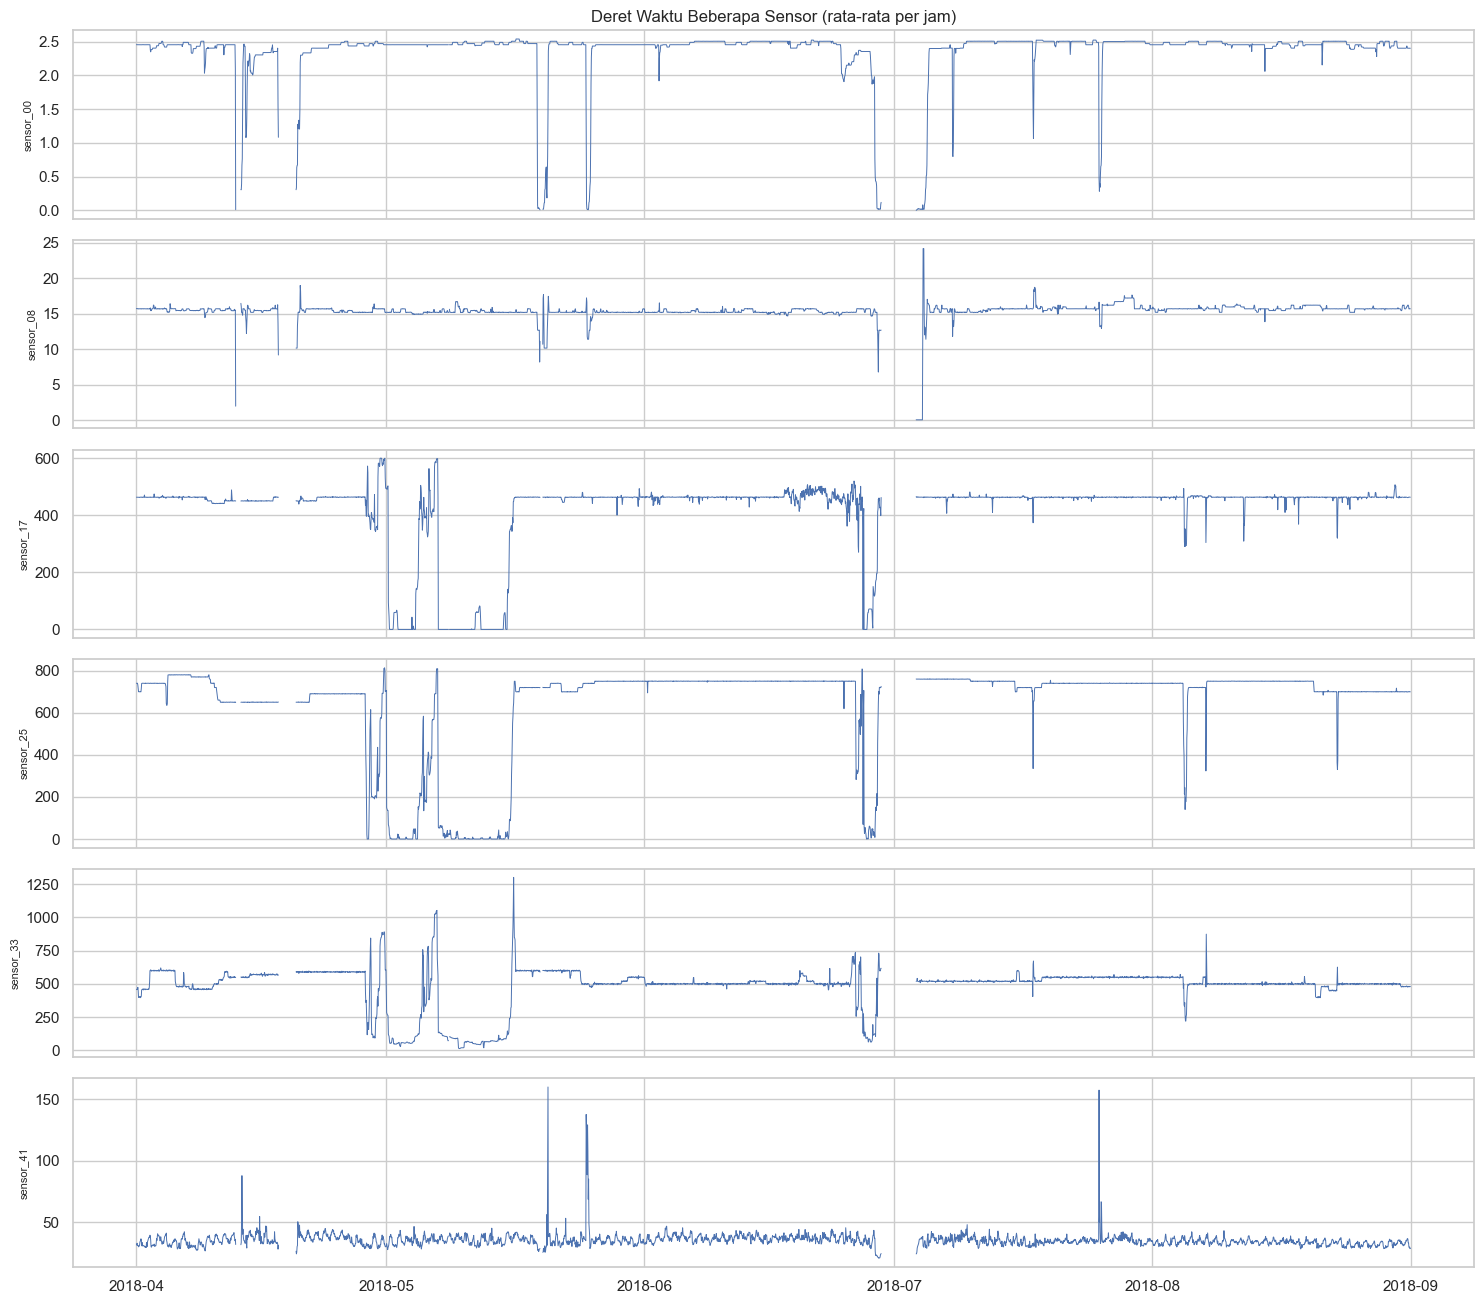

In [11]:
show = feat_cols[::8][:6]
fig, axes = plt.subplots(len(show), 1, figsize=(15, 2.2 * len(show)), sharex=True)
hourly = df_clean[show].resample("1h").mean()
for ax, c in zip(axes, show):
    ax.plot(hourly.index, hourly[c], lw=0.7)
    ax.set_ylabel(c, fontsize=8)
axes[0].set_title("Deret Waktu Beberapa Sensor (rata-rata per jam)")
plt.tight_layout()
plt.show()

Autokorelasi lag-1 (menit): min = 0.926, median = 0.996
Autokorelasi lag-60 (1 jam): median = 0.931


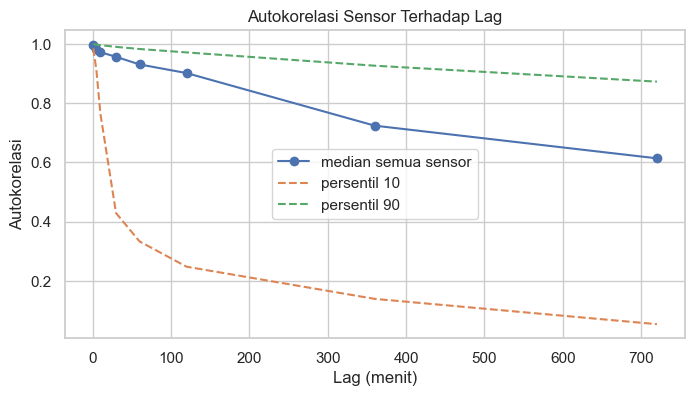

In [12]:
lags = [1, 5, 10, 30, 60, 120, 360, 720]
acf = pd.DataFrame({l: df_clean.apply(lambda s: s.autocorr(l)) for l in lags})
print("Autokorelasi lag-1 (menit): min = %.3f, median = %.3f" % (acf[1].min(), acf[1].median()))
print("Autokorelasi lag-60 (1 jam): median = %.3f" % acf[60].median())

fig, ax = plt.subplots(figsize=(8, 4))
acf.median().plot(marker="o", ax=ax, label="median semua sensor")
acf.quantile(0.1).plot(ls="--", ax=ax, label="persentil 10")
acf.quantile(0.9).plot(ls="--", ax=ax, label="persentil 90")
ax.set_xlabel("Lag (menit)"); ax.set_ylabel("Autokorelasi"); ax.set_title("Autokorelasi Sensor Terhadap Lag")
ax.legend(); plt.show()

Autokorelasi yang tinggi pada lag kecil menunjukkan rekaman bertetangga sangat bergantung satu sama lain, jadi tiap baris tidak boleh diperlakukan sebagai sampel independen. Ini mendasari rancangan **window-based feature extraction** di Tahap 3.

## 7. Analisis Korelasi Antar-Sensor

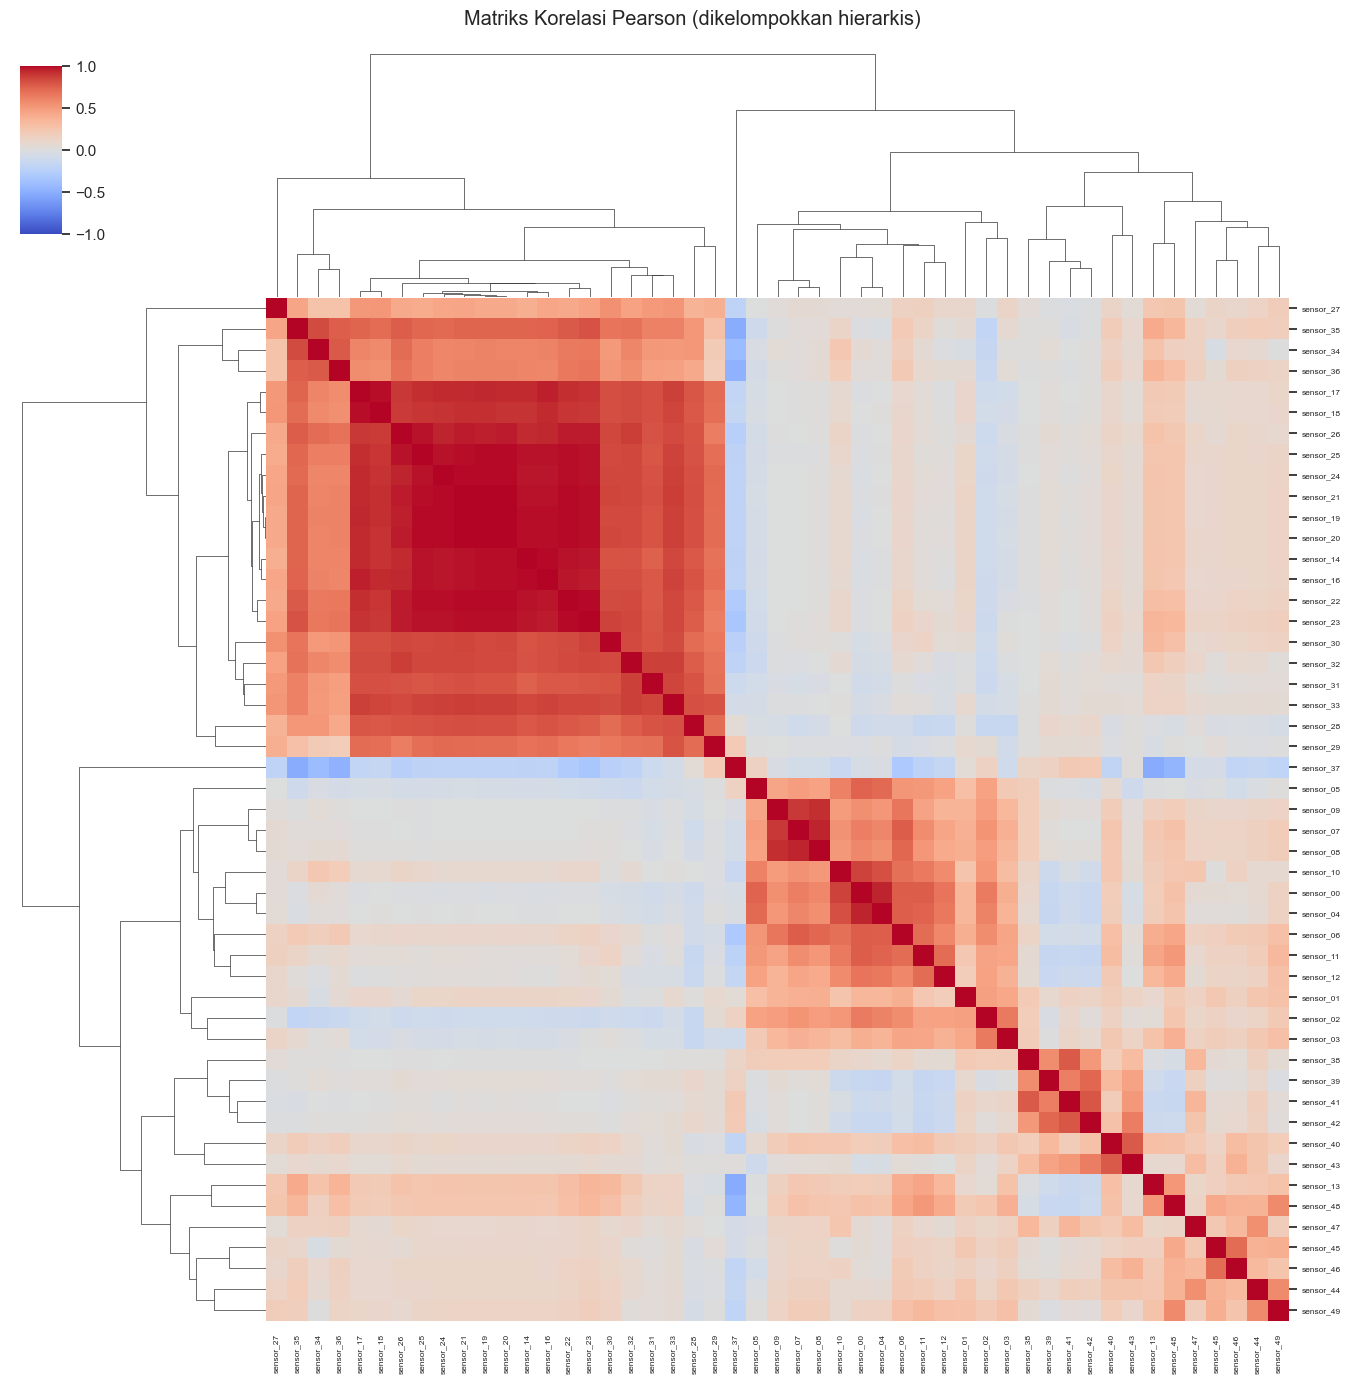

In [13]:
corr = df_clean.corr(method="pearson")
g = sns.clustermap(corr, cmap="coolwarm", vmin=-1, vmax=1, figsize=(14, 14),
                   xticklabels=True, yticklabels=True, cbar_pos=(0.02, 0.85, 0.03, 0.12))
g.ax_heatmap.tick_params(labelsize=6)
g.fig.suptitle("Matriks Korelasi Pearson (dikelompokkan hierarkis)", y=1.01)
plt.show()

In [14]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().reset_index()
pairs.columns = ["sensor_1", "sensor_2", "r"]
pairs["abs_r"] = pairs["r"].abs()

print(f"Pasangan |r| >= 0.9 : {(pairs.abs_r >= 0.9).sum()}")
print(f"Pasangan |r| >= 0.7 : {(pairs.abs_r >= 0.7).sum()}")
print(f"Total pasangan      : {len(pairs)}")
print("\n10 pasangan korelasi tertinggi:")
display(pairs.sort_values("abs_r", ascending=False).head(10))

print("Rata-rata |r| per sensor (tertinggi):")
mean_abs = corr.abs().where(~np.eye(len(corr), dtype=bool)).mean().sort_values(ascending=False)
print(mean_abs.head(8).round(3).to_string())

Pasangan |r| >= 0.9 : 64
Pasangan |r| >= 0.7 : 175
Total pasangan      : 1176

10 pasangan korelasi tertinggi:
      sensor_1   sensor_2     r  abs_r
711  sensor_19  sensor_20 0.998  0.998
741  sensor_20  sensor_21 0.997  0.997
712  sensor_19  sensor_21 0.996  0.996
581  sensor_14  sensor_16 0.990  0.990
713  sensor_19  sensor_22 0.989  0.989
715  sensor_19  sensor_24 0.988  0.988
742  sensor_20  sensor_22 0.987  0.987
772  sensor_21  sensor_24 0.987  0.987
798  sensor_22  sensor_23 0.987  0.987
744  sensor_20  sensor_24 0.986  0.986
Rata-rata |r| per sensor (tertinggi):
sensor_23   0.428
sensor_22   0.420
sensor_21   0.416
sensor_19   0.415
sensor_20   0.415
sensor_24   0.413
sensor_25   0.412
sensor_26   0.411


**Interpretasi:** jika banyak pasangan sensor berkorelasi tinggi, berarti ada **redundansi** dan dimensi efektif data lebih kecil dari 49. Ini yang membenarkan penggunaan **PCA** sebelum K-Means/GMM (mengurangi multikolinearitas dan menekan efek *curse of dimensionality*).

## 8. Analisis Outlier
Dua pendekatan: aturan IQR (1.5×IQR) dan |z-score| > 3. Visualisasi dengan boxplot dan scatter plot.

In [15]:
z = (df_clean - df_clean.mean()) / df_clean.std()
Q1, Q3 = df_clean.quantile(0.25), df_clean.quantile(0.75)
IQR = Q3 - Q1
iqr_out = ((df_clean < Q1 - 1.5 * IQR) | (df_clean > Q3 + 1.5 * IQR))
z_out = z.abs() > 3

outlier_tbl = pd.DataFrame({
    "outlier_IQR_%": iqr_out.mean() * 100,
    "outlier_|z|>3_%": z_out.mean() * 100,
    "max_|z|": z.abs().max(),
}).sort_values("outlier_IQR_%", ascending=False)
display(outlier_tbl.head(12).round(2))

print(f"\nRata-rata outlier IQR per sensor  : {outlier_tbl['outlier_IQR_%'].mean():.2f}%")
print(f"Baris dengan >=1 sensor |z|>3     : {(z_out.sum(axis=1) >= 1).mean()*100:.2f}%")
print(f"Baris dengan >=5 sensor |z|>3     : {(z_out.sum(axis=1) >= 5).mean()*100:.2f}%")

           outlier_IQR_%  outlier_|z|>3_%  max_|z|
sensor_09         30.230            1.310   10.760
sensor_20         26.820            0.140    3.460
sensor_19         26.150            0.000    2.900
sensor_14         26.050            0.000    2.970
sensor_21         25.250            0.000    3.020
sensor_16         22.050            2.030    3.230
sensor_17         18.050            7.220    3.190
sensor_18         18.030            0.020    3.300
sensor_30         17.240            0.390    4.960
sensor_31         15.030            1.300    3.300
sensor_27         15.000            2.310    9.040
sensor_24         14.570            0.000    2.990

Rata-rata outlier IQR per sensor  : 9.79%
Baris dengan >=1 sensor |z|>3     : 21.08%
Baris dengan >=5 sensor |z|>3     : 3.41%


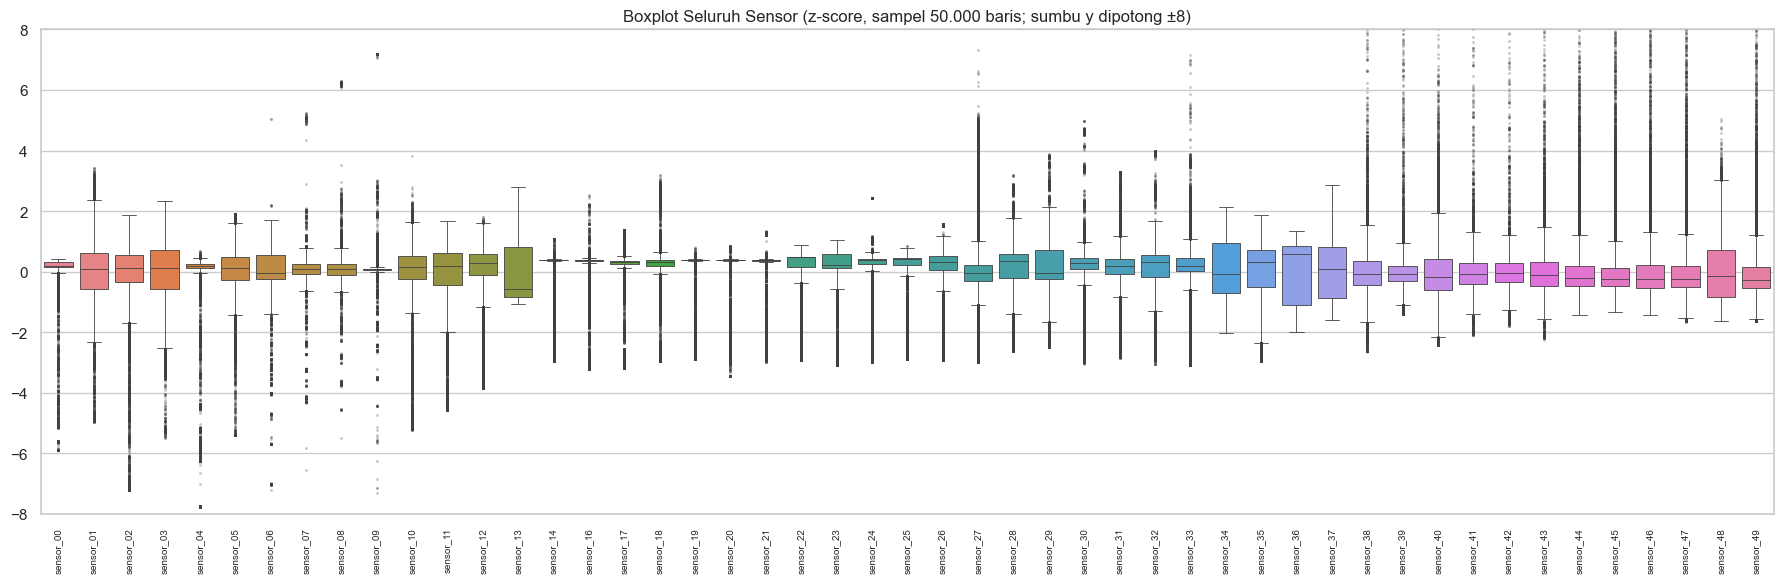

In [16]:
# Boxplot seluruh sensor pada skala z-score agar sebanding
zs = z.sample(50000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(18, 6))
sns.boxplot(data=zs, ax=ax, fliersize=1, linewidth=0.6, flierprops={"alpha": 0.3})
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7)
ax.set_ylim(-8, 8)
ax.set_title("Boxplot Seluruh Sensor (z-score, sampel 50.000 baris; sumbu y dipotong ±8)")
plt.tight_layout(); plt.show()

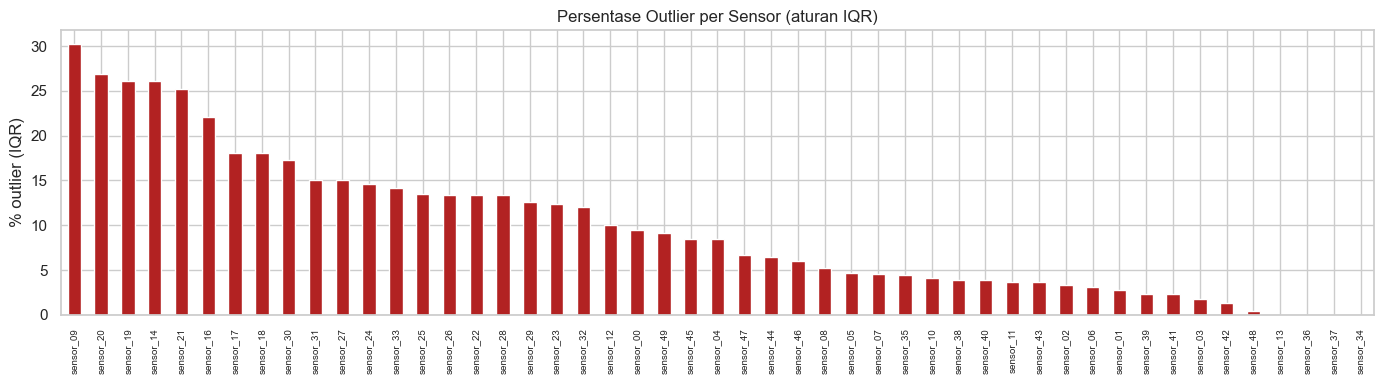

In [17]:
fig, ax = plt.subplots(figsize=(14, 4))
outlier_tbl["outlier_IQR_%"].sort_values(ascending=False).plot.bar(ax=ax, color="firebrick")
ax.set_ylabel("% outlier (IQR)"); ax.set_title("Persentase Outlier per Sensor (aturan IQR)")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

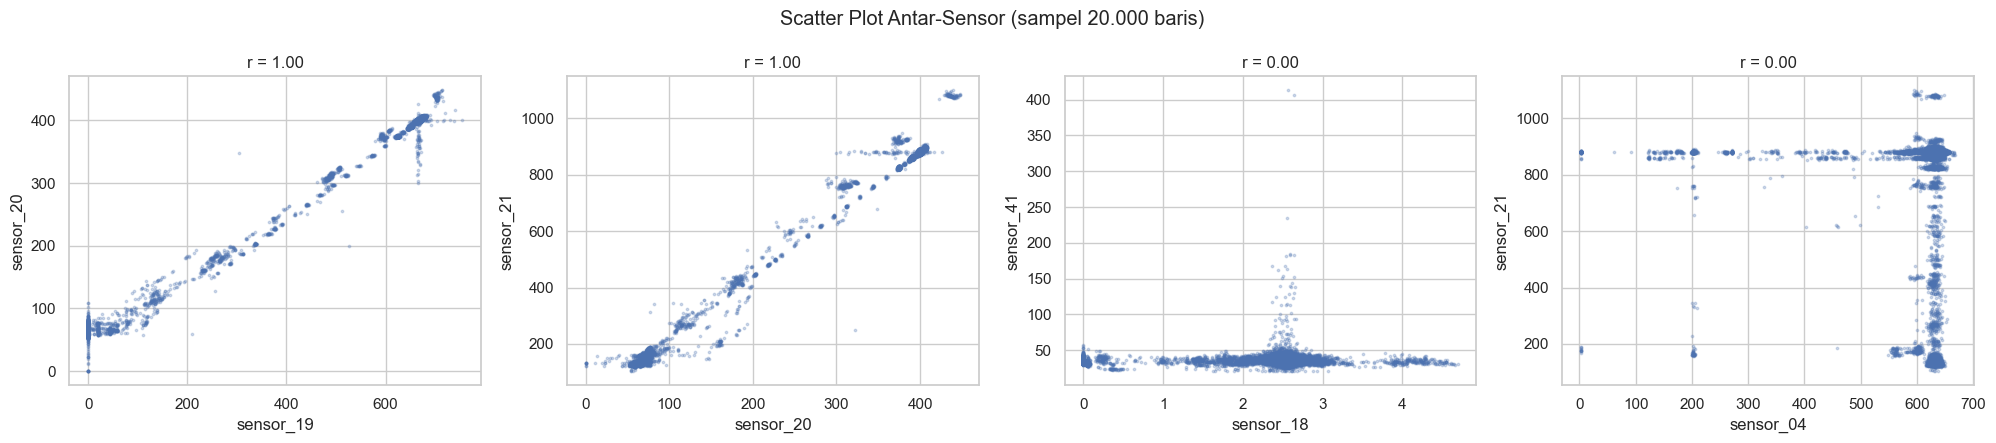

In [18]:
# Scatter plot: 2 pasangan berkorelasi tertinggi + 2 pasangan hampir tidak berkorelasi
top = pairs.sort_values("abs_r", ascending=False).head(2)
low = pairs.sort_values("abs_r").head(2)
chosen = pd.concat([top, low])
samp = df_clean.sample(SAMPLE_N, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (_, r) in zip(axes, chosen.iterrows()):
    ax.scatter(samp[r.sensor_1], samp[r.sensor_2], s=3, alpha=0.25)
    ax.set_xlabel(r.sensor_1); ax.set_ylabel(r.sensor_2)
    ax.set_title(f"r = {r.r:.2f}")
plt.suptitle("Scatter Plot Antar-Sensor (sampel 20.000 baris)")
plt.tight_layout(); plt.show()

**Keputusan sementara, bukan klasifikasi pasti:** aturan IQR dan z-score menandai kandidat nilai ekstrem, tetapi tidak membuktikan bahwa nilai tersebut adalah kesalahan sensor. Pada *operational condition clustering*, nilai ekstrem dapat mewakili kondisi operasi yang bermakna. Karena itu nilai ekstrem **tidak dihapus pada tahap ini**. Dampaknya diuji/diredam dengan:
- memakai **RobustScaler** (median & IQR) atau membandingkannya dengan StandardScaler,
- opsional clipping setelah scaling pada batas ±5 unit skala (sesuai rancangan Tahap 3), diuji sebagai pilihan preprocessing,
- ekstraksi fitur window (mean, std, min, max) yang merangkum lonjakan sesaat.

## 9. Gambaran Struktur Data (PCA) — Pendukung Rancangan Klasterisasi
Hanya untuk eksplorasi: berapa dimensi efektif data, dan apakah ada struktur kelompok.

Komponen untuk 80% variansi: 8
Komponen untuk 90% variansi: 15
Komponen untuk 95% variansi: 23


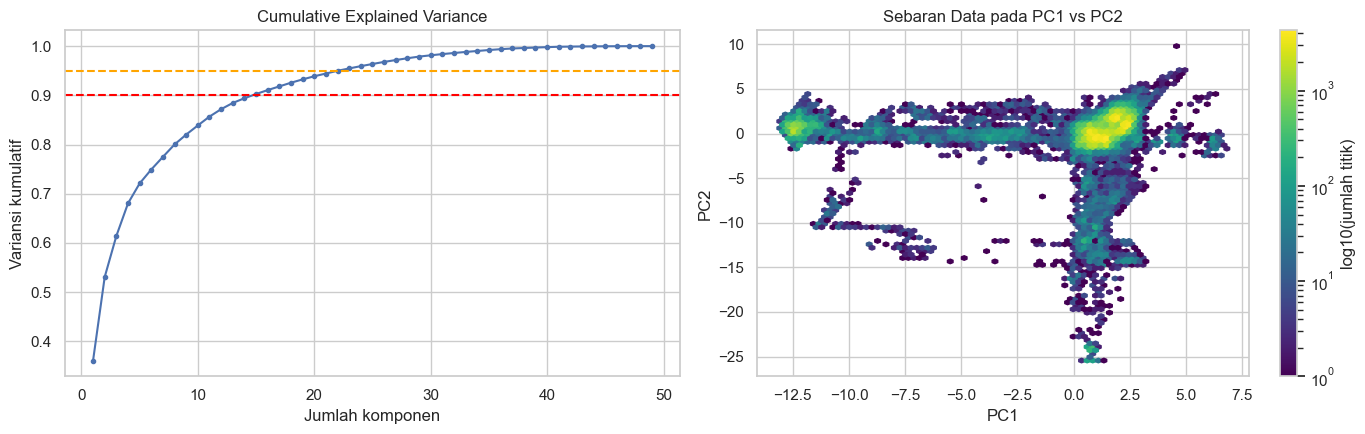

In [19]:
Xs = StandardScaler().fit_transform(df_clean)
pca = PCA(random_state=RANDOM_STATE).fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
for t in (0.80, 0.90, 0.95):
    print(f"Komponen untuk {int(t*100)}% variansi: {np.argmax(cum >= t) + 1}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(range(1, len(cum) + 1), cum, marker="o", ms=3)
ax[0].axhline(0.9, color="red", ls="--"); ax[0].axhline(0.95, color="orange", ls="--")
ax[0].set_xlabel("Jumlah komponen"); ax[0].set_ylabel("Variansi kumulatif"); ax[0].set_title("Cumulative Explained Variance")

pcs = pca.transform(Xs)[:, :2]
hb = ax[1].hexbin(pcs[:, 0], pcs[:, 1], gridsize=80, bins="log", cmap="viridis")
plt.colorbar(hb, ax=ax[1], label="log10(jumlah titik)")
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("Sebaran Data pada PC1 vs PC2")
plt.tight_layout(); plt.show()

Jika sebaran PC1–PC2 menunjukkan beberapa area padat yang terpisah, itu mendukung dugaan adanya beberapa kondisi operasional yang berbeda.

## 10. Rencana Preprocessing (Preprocessing Plan)
| No | Permasalahan | Bukti dari EDA | Keputusan |
|---|---|---|---|
| 1 | Label status tersedia di file sumber | kolom `machine_status` | Dikeluarkan dari fitur dan proses clustering; hanya boleh dipakai untuk validasi eksternal pasca-clustering jika dosen mengizinkan |
| 2 | Sensor hampir/seluruhnya kosong | `sensor_15`, `sensor_50`, `sensor_51` | Dibuang (missing > 5%) |
| 3 | Missing berupa blok panjang | gap terpanjang hingga berhari-hari | Interpolasi hanya gap ≤ 60 menit; sisanya baris dibuang & dicatat sebagai putus waktu |
| 4 | Ketimpangan skala | rasio std antar-sensor sangat besar | Scaling wajib (RobustScaler / StandardScaler) |
| 5 | Distribusi miring | banyak sensor dengan skewness absolut > 1 | Pilih scaler robust; opsional winsorizing |
| 6 | Ketergantungan waktu | autokorelasi tinggi pada lag kecil | Window-based feature extraction, window tidak boleh melintasi gap waktu |
| 7 | Redundansi antar-sensor | banyak pasangan dengan korelasi absolut ≥ 0.9 | PCA (target ±90–95% variansi) |
| 8 | Outlier | % outlier IQR per sensor | Tidak dihapus; ditangani lewat scaler robust dan fitur window |

**Alur yang diusulkan untuk Tahap 3:**
`data bersih → windowing per segmen kontinu → scaling → PCA → K-Means dan/atau GMM → evaluasi (Elbow untuk K-Means; BIC/AIC untuk GMM; metrik internal sebagai pelengkap)`

In [20]:
print("=== RINGKASAN PREPROCESSING ===")
print(f"Sensor awal              : {len(sensor_cols)}")
print(f"Sensor dibuang           : {len(drop_sensors)} -> {drop_sensors}")
print(f"Sensor dipakai           : {df_clean.shape[1]}")
print(f"Baris awal               : {len(df):,}")
print(f"Baris bersih             : {len(df_clean):,} ({len(df_clean)/len(df)*100:.1f}%)")
print(f"Segmen waktu kontinu     : {seg_id.nunique()}")

# Simpan hasil untuk Tahap 3 (kolom segment dipakai agar window tidak melintasi gap)
out = df_clean.copy()
out["segment"] = seg_id.values
clean_path = OUTPUT_DIR / "sensor_clean_unlabeled_local.csv"
out.to_csv(clean_path)
print(f"\nTersimpan: {clean_path.resolve()}")

=== RINGKASAN PREPROCESSING ===
Sensor awal              : 52
Sensor dibuang           : 3 -> ['sensor_15', 'sensor_50', 'sensor_51']
Sensor dipakai           : 49
Baris awal               : 220,320
Baris bersih             : 209,548 (95.1%)
Segmen waktu kontinu     : 7

Tersimpan: C:\KULIAH\SEMESTER 5\Data mining\UTS Data Mining\Dataset\sensor_clean_unlabeled_local.csv
